Aflevering 3

zvp380/Josefine Rosenfeldt

8.oktober

In [85]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cars.csv')
pd.set_option('display.float_format', '{:.5f}'.format)
df.describe(percentiles=[]).T

,count,mean,std,min,50%,max
year,9694.00000,2001.09676,11.07696,1980.00000,2002.00000,2018.00000
product_id,9694.00000,486.67495,278.99753,0.00000,512.00000,1066.00000
sales,9694.00000,59103.39104,86940.25408,10.00000,27394.00000,891482.00000
number_households,9694.00000,107213264.90613,13932786.27747,80780000.00000,109300000.00000,127590000.00000
price,9694.00000,36.04769,17.12656,11.14478,31.82023,99.98639
height,9694.00000,60.94814,8.41152,43.50000,57.70000,107.50000
footprint,9694.00000,13392.63000,1968.91519,6514.54000,13330.06400,21821.85900
weight,9694.00000,3561.21114,897.76553,1113.00000,3470.50000,8550.00000
hp,9694.00000,192.18197,83.88244,44.00000,175.00000,645.00000
mpg,9694.00000,20.93615,6.58300,10.00000,19.00000,50.00000


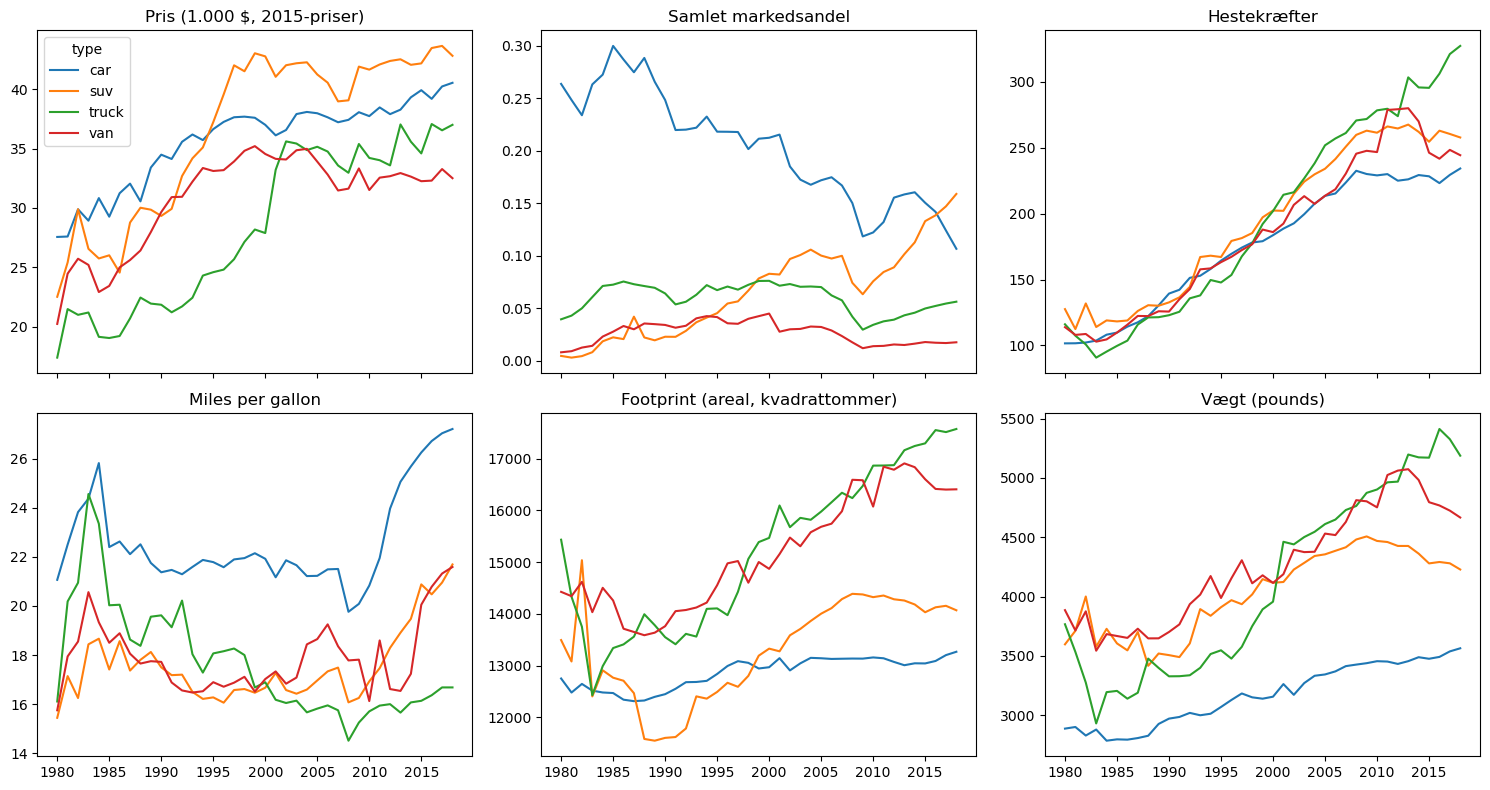

In [86]:
#1A

import matplotlib.pyplot as plt
import seaborn as sns

# Én variabel for biltype ud fra de gensidigt udelukkende dummies
types = ['car', 'suv', 'truck', 'van']
df['type'] = df[types].idxmax(axis=1)

# Gennemsnit pr. år og biltype
vars_mean = ['price', 'hp', 'mpg', 'footprint', 'weight']
by_year = df.groupby(['year', 'type'])[vars_mean].mean().reset_index()

# Samlet markedsandel pr. år og biltype
share = df.groupby(['year', 'type'])['market_share'].sum().reset_index()

labels = {
    'price': 'Pris (1.000 $, 2015-priser)',
    'market_share': 'Samlet markedsandel',
    'hp': 'Hestekræfter',
    'mpg': 'Miles per gallon',
    'footprint': 'Footprint (areal, kvadrattommer)',
    'weight': 'Vægt (pounds)',
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, var in zip(axes.flat, labels):
    data = share if var == 'market_share' else by_year
    sns.lineplot(data=data, x='year', y=var, hue='type', ax=ax,
                 legend='auto' if var == 'price' else False)
    ax.set_title(labels[var])
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.tight_layout()
plt.savefig('fig_1a_tid.png', dpi=300, bbox_inches='tight')
plt.show()



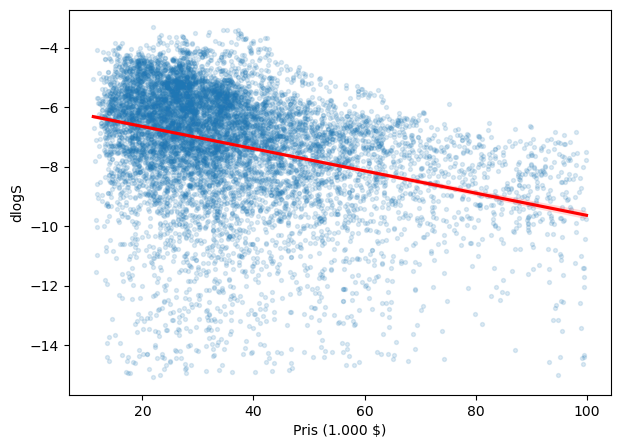

In [87]:
#1A

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=df, x='price', y='dlogS', ax=ax,
            scatter_kws={'alpha': 0.15, 's': 8}, line_kws={'color': 'red'})
ax.set_xlabel('Pris (1.000 $)')
ax.set_ylabel('dlogS')
plt.savefig('fig_1a_dlogS_pris.png', dpi=300, bbox_inches='tight')
plt.show()


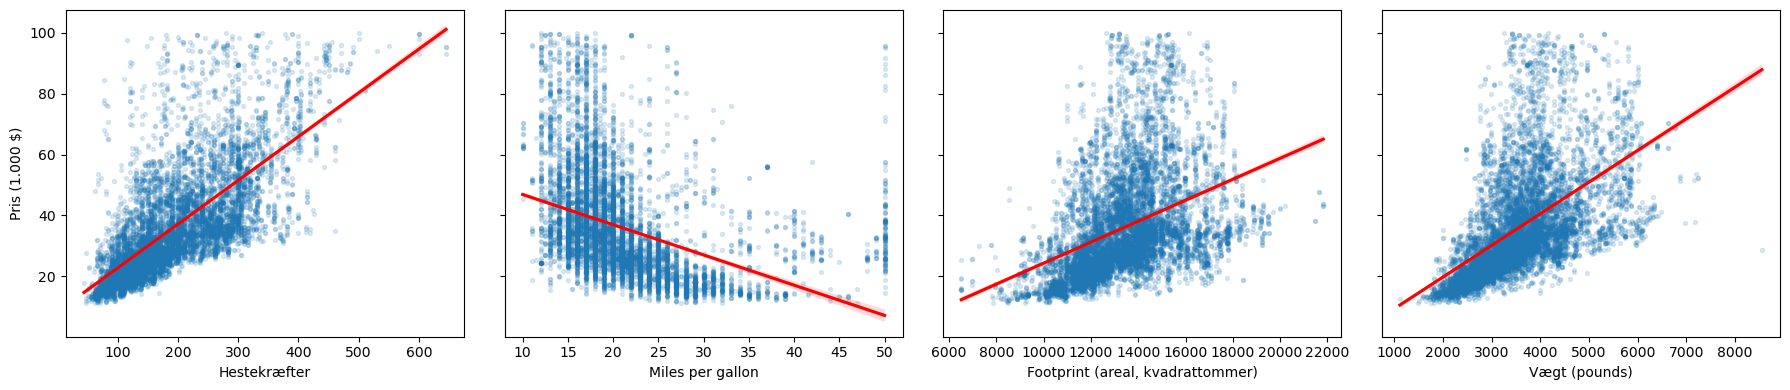

In [88]:
#1A

attrs = ['hp', 'mpg', 'footprint', 'weight']
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, var in zip(axes, attrs):
    sns.regplot(data=df, x=var, y='price', ax=ax,
                scatter_kws={'alpha': 0.15, 's': 8}, line_kws={'color': 'red'})
    ax.set_xlabel(labels[var])
    ax.set_ylabel('Pris (1.000 $)' if var == 'hp' else '')
fig.tight_layout()
plt.savefig('fig_1a_pris_egenskaber.png', dpi=300, bbox_inches='tight')
plt.show()


In [89]:
#1B - Specifikation 1

df['const'] = 1 #tilføjer en konstant
X = df[['const', 'price']].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"beta_0: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"alpha_hat: estimat = {alpha_hat[1]:.4f}, std. fejl = {se_alpha[1]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat1, se_alpha1 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C

beta_0: estimat = -5.9072, std. fejl = 0.0439
alpha_hat: estimat = -0.0373, std. fejl = 0.0011
TSS = 37300.70
ESS = 3961.22
RSS = 33339.47
R2 = 0.1062


In [90]:
#1B - Specifikation 2

#Dummies
df['sport'] = (df['sport'] == 1).astype(int)
df['EV'] = (df['EV'] == 1).astype(int)
df['truck'] = (df['truck'] == 1).astype(int)
df['suv'] = (df['suv'] == 1).astype(int)
df['van'] = (df['van'] == 1).astype(int)

x = ['const', 'price', 'hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van']

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"beta_0: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"alpha_hat: estimat = {alpha_hat[1]:.4f}, std. fejl = {se_alpha[1]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat2, se_alpha2 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C

beta_0: estimat = -5.4138, std. fejl = 0.2908
alpha_hat: estimat = -0.0243, std. fejl = 0.0016
TSS = 37300.70
ESS = 11192.33
RSS = 26108.36
R2 = 0.3001


In [91]:
#1B - Specifikation 3

#Fjern gamle dummyer
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')])

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)

#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

x = ['const', 'price', 'hp', 'mpg', 'height', 'footprint', 'weight', 
     'number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"beta_0: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"alpha_hat: estimat = {alpha_hat[1]:.4f}, std. fejl = {se_alpha[1]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat3, se_alpha3 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C

beta_0: estimat = -6.8066, std. fejl = 0.3177
alpha_hat: estimat = -0.0370, std. fejl = 0.0017
TSS = 37300.70
ESS = 12720.23
RSS = 24580.47
R2 = 0.3410


In [92]:
#1B - Specifikation 4

#Fjern gamle dummyer
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')])

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)

#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

x = ['const', 'price', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 
     'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"beta_0: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"alpha_hat: estimat = {alpha_hat[1]:.4f}, std. fejl = {se_alpha[1]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")

alpha_hat4, se_alpha4 = alpha_hat, se_alpha #omdøber, så de kan bruges til 1C

beta_0: estimat = -25.4344, std. fejl = 1.6540
alpha_hat: estimat = -0.0298, std. fejl = 0.0014
TSS = 37300.70
ESS = 18893.65
RSS = 18407.04
R2 = 0.5065


In [93]:
#1C 

#t-værdier
t1 = alpha_hat1[1] / se_alpha1[1]
t2 = alpha_hat2[1] / se_alpha2[1]
t3 = alpha_hat3[1] / se_alpha3[1]
t4 = alpha_hat4[1] / se_alpha4[1]

print(f"Specifikation 1: t = {t1:.2f}")
print(f"Specifikation 2: t = {t2:.2f}")
print(f"Specifikation 3: t = {t3:.2f}")
print(f"Specifikation 4: t = {t4:.2f}")

Specifikation 1: t = -33.93
Specifikation 2: t = -15.06
Specifikation 3: t = -21.90
Specifikation 4: t = -20.97


In [ ]:
#2A - make-dummies

df = df.drop(columns=[c for c in df.columns if c.startswith('m_')]) #Fjern gamle make-dummies
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')]) #Fjern gamle tids-dummies

#Add dummies for 'make' (bilmærke)
make_dummies = pd.get_dummies(df['make'], prefix = 'm', drop_first =True, dtype=int)
df = pd.concat([df, make_dummies], axis=1)

#Store brand variable names for later use
brand = list(make_dummies.columns) #['m_toyota', 'm_audi'...]

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)

#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

df['log_hp'] = np.log(df['hp'])
df['log_mpg'] = np.log(df['mpg'])
df['log_height'] = np.log(df['height'])
df['log_footprint'] = np.log(df['footprint'])
df['log_weight'] = np.log(df['weight'])
df['log_number_trims'] = np.log(df['number_trims'])

x = ['const', 'price', 'log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 
     'log_number_trims', 'releaseYear', 'yearsSinceDesign', 'sport', 'EV', 'truck', 'suv', 'van'] + years + brand

X = df[x].values #forklarende variable
y = df['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1] - 1  # antal forklarende variable (kolonner) (ikke inkl. konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = beta_0, alpha_hat[1] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k-1)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"beta_0: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"alpha_hat: estimat = {alpha_hat[1]:.4f}, std. fejl = {se_alpha[1]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")


beta_0: estimat = -15.1108, std. fejl = 1.7284
alpha_hat: estimat = -0.0337, std. fejl = 0.0017
TSS = 37300.70
ESS = 21967.19
RSS = 15333.51
R2 = 0.5889


In [109]:
#2A - within-transformation

df = df.drop(columns=[c for c in df.columns if c.startswith('m_')]) #Fjern gamle make-dummies
df = df.drop(columns=[c for c in df.columns if c.startswith('y_')]) #Fjern gamle tids-dummies

#Add dummies for 'year'
year_dummies = pd.get_dummies(df['year'], prefix = 'y', drop_first =True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)
#Store year variable names for later use
years = list(year_dummies.columns) #['y_1981', 'y_1982'...]

#within-transformation
df_within = df.copy()
vars_to_transform = ['dlogS', 'price', 'log_hp', 'log_mpg', 'log_height', 'log_footprint',
                     'log_weight', 'log_number_trims', 'releaseYear', 'yearsSinceDesign',
                     'sport', 'EV', 'truck', 'suv', 'van'] + years

for var in vars_to_transform:
    make_mean = df.groupby('make')[var].transform('mean')
    df_within[var] = df[var] - make_mean

X = df_within[vars_to_transform[1:]].values #alle variable undtagem dlogS
y = df_within['dlogS'].values

n = X.shape[0] #antal rækker = 9694
k = X.shape[1]  # antal forklarende variable (kolonner) (ingen konstant)

alpha_hat = np.linalg.inv(X.T @ X) @ X.T @ y # alpha_hat[0] = alpha_hat

y_hat = X @ alpha_hat
residualer = y - y_hat

TSS = np.sum((y - y.mean())**2)        # total sum of squares
ESS = np.sum((y_hat - y.mean())**2)    # explained sum of squares
RSS = np.sum(residualer**2)            # sum of squared residuals
R2 = ESS / TSS

sigma2_hat = RSS/(n-k)
se_alpha = np.sqrt(np.diag(sigma2_hat * np.linalg.inv(X.T @ X))) #standarderror

print(f"alpha_hat: estimat = {alpha_hat[0]:.4f}, std. fejl = {se_alpha[0]:.4f}")
print(f"TSS = {TSS:.2f}")
print(f"ESS = {ESS:.2f}")
print(f"RSS = {RSS:.2f}")
print(f"R2 = {R2:.4f}")


alpha_hat: estimat = -0.0337, std. fejl = 0.0017
TSS = 30415.61
ESS = 15082.11
RSS = 15333.51
R2 = 0.4959


In [95]:
#4C -  Scenarie 1

def simulate(n):

    ## Parameterværdier
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25
    gamma1 = 1.0
    gamma2 = 1.0

    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)

    # Simuler data
    z  = np.random.normal(loc=0, scale=1, size=n)   # z ~ N(0,1)
    xi = np.random.normal(loc=0, scale=1, size=n)   # xi ~ N(0,1)
    v  = np.random.normal(loc=0, scale=1, size=n)   # v ~ N(0,1)

    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u
    y = beta0 + beta1*p + xi

    ## OLS: Cov(p, y) / Var(p)
    beta1_OLS = np.cov(p, y)[0, 1] / np.var(p, ddof=1)

    ## IV: Cov(z, y) / Cov(z, p)
    beta1_IV = np.cov(z, y)[0, 1] / np.cov(z, p)[0, 1]

    return beta1_OLS, beta1_IV


def monte_carlo(n, reps=500):
    np.random.seed(0)
    out = []

    for rep in range(reps):
        out.append(simulate(n))

    results = pd.DataFrame(out, columns=['beta1_OLS', 'beta1_IV'])

    return results


res = monte_carlo(n=500, reps=500)
print('Gennemsnit:\n', res.mean().round(5))
print('Bias:\n', (res.mean() - (-0.1)).round(5))
print('Varians:\n', res.var(ddof=1).round(5))

Gennemsnit:
 beta1_OLS    0.26753
beta1_IV    -0.10030
dtype: float64
Bias:
 beta1_OLS    0.36753
beta1_IV    -0.00030
dtype: float64
Varians:
 beta1_OLS   0.00056
beta1_IV    0.00236
dtype: float64


In [96]:
#4C -  Scenarie 2

def simulate(n):

    ## Parameterværdier
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25
    gamma1 = 1.0
    gamma2 = 0.25

    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)

    # Simuler data
    z  = np.random.normal(loc=0, scale=1, size=n)   # z ~ N(0,1)
    xi = np.random.normal(loc=0, scale=1, size=n)   # xi ~ N(0,1)
    v  = np.random.normal(loc=0, scale=1, size=n)   # v ~ N(0,1)

    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u
    y = beta0 + beta1*p + xi

    ## OLS: Cov(p, y) / Var(p)
    beta1_OLS = np.cov(p, y)[0, 1] / np.var(p, ddof=1)

    ## IV: Cov(z, y) / Cov(z, p)
    beta1_IV = np.cov(z, y)[0, 1] / np.cov(z, p)[0, 1]

    return beta1_OLS, beta1_IV


def monte_carlo(n, reps=500):
    np.random.seed(0)
    out = []

    for rep in range(reps):
        out.append(simulate(n))

    results = pd.DataFrame(out, columns=['beta1_OLS', 'beta1_IV'])

    return results


res = monte_carlo(n=500, reps=500)
print('Gennemsnit:\n', res.mean().round(5))
print('Bias:\n', (res.mean() - (-0.1)).round(5))
print('Varians:\n', res.var(ddof=1).round(5))

Gennemsnit:
 beta1_OLS    0.43391
beta1_IV    -0.13065
dtype: float64
Bias:
 beta1_OLS    0.53391
beta1_IV    -0.03065
dtype: float64
Varians:
 beta1_OLS   0.00064
beta1_IV    0.05343
dtype: float64


In [97]:
#4C - Scenarie 3

def simulate(n):

    ## Parameterværdier
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25
    gamma1 = 0.25
    gamma2 = 1.0

    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)

    # Simuler data
    z  = np.random.normal(loc=0, scale=1, size=n)   # z ~ N(0,1)
    xi = np.random.normal(loc=0, scale=1, size=n)   # xi ~ N(0,1)
    v  = np.random.normal(loc=0, scale=1, size=n)   # v ~ N(0,1)

    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u
    y = beta0 + beta1*p + xi

    ## OLS: Cov(p, y) / Var(p)
    beta1_OLS = np.cov(p, y)[0, 1] / np.var(p, ddof=1)

    ## IV: Cov(z, y) / Cov(z, p)
    beta1_IV = np.cov(z, y)[0, 1] / np.cov(z, p)[0, 1]

    return beta1_OLS, beta1_IV


def monte_carlo(n, reps=500):
    np.random.seed(0)
    out = []

    for rep in range(reps):
        out.append(simulate(n))

    results = pd.DataFrame(out, columns=['beta1_OLS', 'beta1_IV'])

    return results


res = monte_carlo(n=500, reps=500)
print('Gennemsnit:\n', res.mean().round(5))
print('Bias:\n', (res.mean() - (-0.1)).round(5))
print('Varians:\n', res.var(ddof=1).round(5))

Gennemsnit:
 beta1_OLS    0.01694
beta1_IV    -0.10010
dtype: float64
Bias:
 beta1_OLS    0.11694
beta1_IV    -0.00010
dtype: float64
Varians:
 beta1_OLS   0.00006
beta1_IV    0.00024
dtype: float64
